# 01 · First look at the NFIP data

**Goal:** get to know the two FEMA datasets before cleaning or modelling anything.

* **Claims** (`NfipClaims` v3): every National Flood Insurance Program claim in the US since the 1970s. One row = one claim.
* **Policies** (`NfipPolicies` v3), Virginia only. One row = one policy term (usually a year of coverage for one building).

Questions this notebook answers:
1. How big is each dataset, and how much is missing?
2. When and where do claims happen (by year, state, county)?
3. What do claim payments look like, and why do we need a log scale to see them?
4. What does Virginia's policy base (our **exposure**) look like?

Data comes from `src/download_data.py`. Field meanings are in `docs/data_dictionary.md`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

# Paths (the notebook lives in notebooks/, so the project root is one level up)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

CLAIMS_FILE = RAW / "NfipClaimsV3.parquet"
POLICIES_FILE = RAW / "NfipPoliciesV3_VA.parquet"

pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 50)

# --- Chart style: one consistent, quiet look for every figure ---------------
BLUE = "#2a78d6"     # main data colour
ORANGE = "#eb6834"   # highlight colour (used only to call out Virginia)
INK, INK_2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS = "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2, "font.size": 10,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})

def save(fig, name):
    # Save a chart to reports/figures/ and show where it went
    path = FIG / f"01_{name}.png"
    fig.savefig(path)
    print(f"saved {path.relative_to(ROOT)}")

def thousands(x, pos=None):
    return f"{x:,.0f}"

def dollars_short(x, pos=None):
    # $500, $10K, $2.5M: short dollar labels so axis ticks don't collide
    if x >= 1e6:
        return f"${x / 1e6:,.0f}M" if x % 1e6 == 0 else f"${x / 1e6:,.1f}M"
    if x >= 1e3:
        return f"${x / 1e3:,.0f}K"
    return f"${x:,.0f}"

def count_short(x, pos=None):
    # 150,000 -> 150K
    return f"{x / 1e3:,.0f}K" if x >= 1e3 else f"{x:,.0f}"

## 1. Load the data

The claims file has 84 columns, but we only load the ones this notebook needs. Parquet stores data column by column, so reading a subset is fast and saves memory.

In [2]:
CLAIM_COLS = [
    "id", "dateOfLoss", "yearOfLoss", "state", "countyCode", "censusGeoid", "reportedZipCode",
    "ratedFloodZone", "occupancyType", "causeOfDamage", "policyCount",
    "amountPaidOnBuildingClaim", "amountPaidOnContentsClaim",
    "amountPaidOnIncreasedCostOfComplianceClaim",
    "netBuildingPaymentAmount", "netContentsPaymentAmount",
    "buildingDamageAmount", "contentsDamageAmount",
    "totalBuildingInsuranceCoverage", "totalContentsInsuranceCoverage",
    "waterDepth", "floodEvent", "nonPaymentReasonBuilding", "primaryResidenceIndicator",
]
claims = pd.read_parquet(CLAIMS_FILE, columns=CLAIM_COLS)
policies = pd.read_parquet(POLICIES_FILE)

import pyarrow.parquet as pq
for name, path, df in [("Claims (US)", CLAIMS_FILE, claims), ("Policies (VA)", POLICIES_FILE, policies)]:
    meta = pq.ParquetFile(path).metadata
    print(f"{name:14s} file: {path.stat().st_size / 1e6:,.0f} MB on disk | "
          f"{meta.num_rows:,} rows x {meta.num_columns} columns in file | "
          f"loaded {df.shape[1]} columns, {df.memory_usage(deep=True).sum() / 1e6:,.0f} MB in memory")

Claims (US)    file: 227 MB on disk | 2,725,989 rows x 84 columns in file | loaded 24 columns, 608 MB in memory
Policies (VA)  file: 52 MB on disk | 1,668,793 rows x 37 columns in file | loaded 37 columns, 559 MB in memory


In [3]:
claims.head(3).T

,0,1,2
id,5448672,5448673,5448674
dateOfLoss,2016-10-08 00:00:00+00:00,2017-08-27 00:00:00+00:00,2017-08-27 00:00:00+00:00
yearOfLoss,2016,2017,2017
state,VA,TX,TX
countyCode,51810,48201,48167
censusGeoid,518100458061,482013430001,481677236003
reportedZipCode,23452,77505,77510
ratedFloodZone,A,X,X
occupancyType,1.00,11.00,11.00
causeOfDamage,4,4,0


## 2. Missing values

A **missing value** is a blank cell: FEMA didn't record it. Missingness matters for modelling. A field that's 90% blank can't be a reliable predictor, and if blanks are concentrated in older years, they can bias results.

In [4]:
def missing_table(df):
    # Share of blank values per column, highest first
    out = pd.DataFrame({"missing": df.isna().sum(), "pct_missing": df.isna().mean() * 100})
    return out.sort_values("pct_missing", ascending=False)

claims_missing = missing_table(claims)
policies_missing = missing_table(policies)
print("CLAIMS: % missing per loaded column")
display(claims_missing)

CLAIMS: % missing per loaded column


,missing,pct_missing
nonPaymentReasonBuilding,2123351,77.89
contentsDamageAmount,1587352,58.23
floodEvent,772772,28.35
buildingDamageAmount,594762,21.82
amountPaidOnContentsClaim,567072,20.80
amountPaidOnIncreasedCostOfComplianceClaim,567072,20.80
amountPaidOnBuildingClaim,567072,20.80
waterDepth,237054,8.70
ratedFloodZone,139030,5.10
censusGeoid,137141,5.03


In [5]:
print("POLICIES (VA): % missing per column")
display(policies_missing)

POLICIES (VA): % missing per column


,missing,pct_missing
cancellationDateOfFloodPolicy,1605546,96.21
elevationDifference,1115054,66.82
basementEnclosureCrawlspaceType,979884,58.72
floodZoneCurrent,500322,29.98
crsClassCode,292321,17.52
contentsDeductibleCode,206993,12.40
buildingReplacementCost,97531,5.84
buildingDeductibleCode,13036,0.78
censusGeoid,7566,0.45
longitude,392,0.02


saved reports\figures\01_missing_values.png


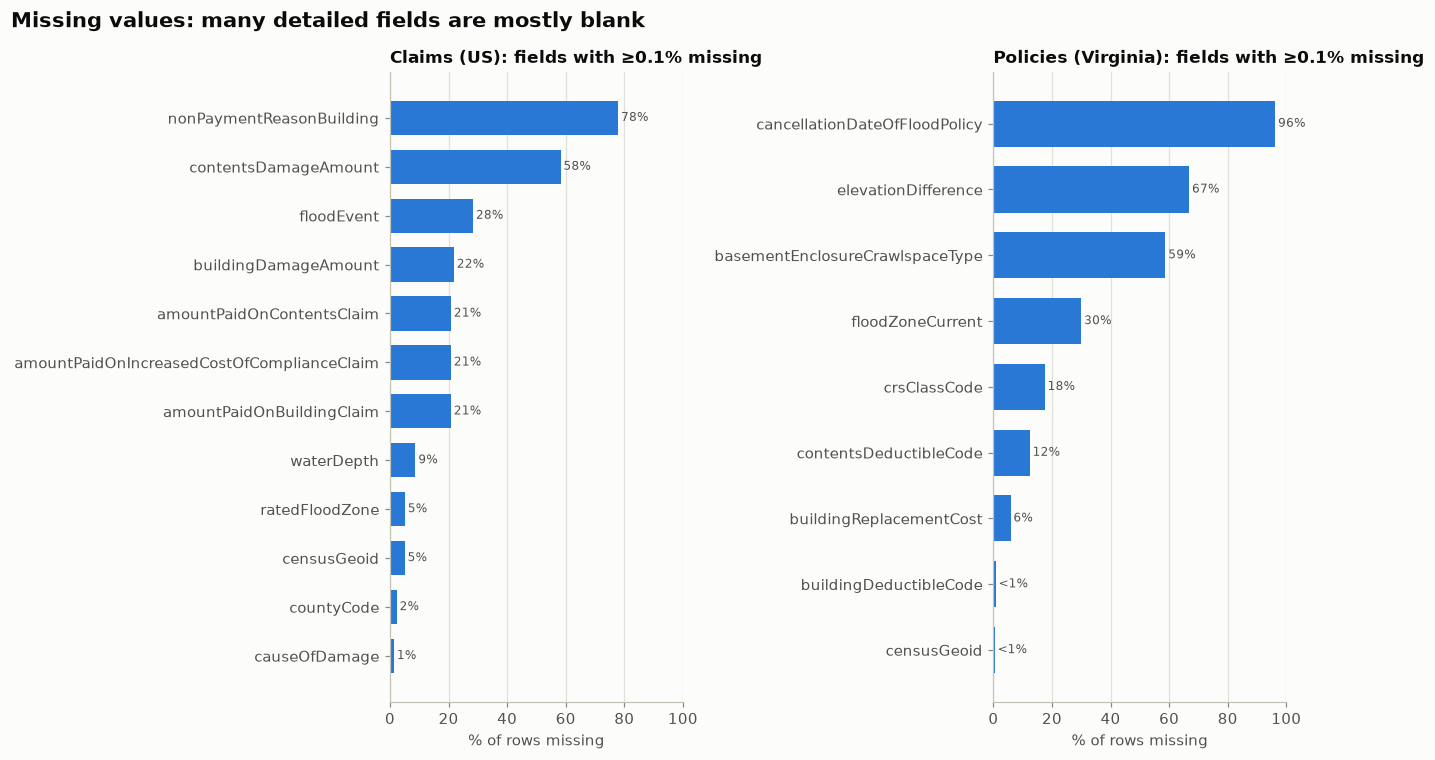

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 7))
for ax, (title, tbl) in zip(axes, [("Claims (US)", claims_missing), ("Policies (Virginia)", policies_missing)]):
    t = tbl[tbl.pct_missing >= 0.1].head(15).iloc[::-1]   # fields with at least 0.1% blank
    ax.barh(t.index, t.pct_missing, color=BLUE, height=0.7)
    ax.set_xlim(0, 100)
    ax.set_xlabel("% of rows missing")
    ax.set_title(f"{title}: fields with ≥0.1% missing", fontsize=11)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(t.pct_missing):
        ax.text(v + 1, y, f"{v:.0f}%" if v >= 1 else "<1%", va="center", fontsize=8, color=INK_2)
fig.suptitle("Missing values: many detailed fields are mostly blank", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "missing_values")
plt.show()

## 3. Quick data-quality checks

Before counting anything, check a few things that commonly go wrong: duplicate IDs, impossible dates, the format of location codes, and negative payments.

In [7]:
print("Duplicate claim ids:      ", claims["id"].duplicated().sum())
print("Duplicate policy ids:     ", policies["id"].duplicated().sum())
print("Year of loss range:       ", claims["yearOfLoss"].min(), "to", claims["yearOfLoss"].max())
print("Date of loss range:       ", claims["dateOfLoss"].min().date(), "to", claims["dateOfLoss"].max().date())
print("Policy effective range:   ", policies["policyEffectiveDate"].min().date(), "to",
      policies["policyEffectiveDate"].max().date())
yr_mismatch = (claims["dateOfLoss"].dt.year != claims["yearOfLoss"]).sum()
print("yearOfLoss != year(dateOfLoss):", yr_mismatch)

print("\ncountyCode text length (how many digits):")
print(claims["countyCode"].str.len().value_counts(dropna=False).sort_index())
print("\nDoes countyCode start with the state's FIPS code? (checked for VA, FIPS 51)")
va_cc = claims.loc[claims.state == "VA", "countyCode"].dropna()
print(f"  {va_cc.str.startswith('51').mean():.1%} of VA claims")
print("\nDoes countyCode match the first 5 digits of censusGeoid?")
both = claims.dropna(subset=["countyCode", "censusGeoid"])
print(f"  {(both.countyCode == both.censusGeoid.str[:5]).mean():.1%} of claims that have both")

print("\ncensusGeoid length in policies:")
print(policies["censusGeoid"].str.len().value_counts(dropna=False).sort_index())

for col in ["amountPaidOnBuildingClaim", "amountPaidOnContentsClaim"]:
    print(f"\n{col}: negative = {(claims[col] < 0).sum():,}, zero = {(claims[col] == 0).sum():,}, "
          f"missing = {claims[col].isna().sum():,}")

Duplicate claim ids:       0
Duplicate policy ids:      0
Year of loss range:        1978 to 2026
Date of loss range:        1978-01-01 to 2026-09-07
Policy effective range:    2009-01-01 to 2026-11-29
yearOfLoss != year(dateOfLoss): 0

countyCode text length (how many digits):
countyCode
5.00    2663556
NaN       62433
Name: count, dtype: int64

Does countyCode start with the state's FIPS code? (checked for VA, FIPS 51)
  100.0% of VA claims

Does countyCode match the first 5 digits of censusGeoid?


  100.0% of claims that have both

censusGeoid length in policies:
censusGeoid
12.00    1661227
NaN         7566
Name: count, dtype: int64

amountPaidOnBuildingClaim: negative = 84, zero = 150,854, missing = 567,072

amountPaidOnContentsClaim: negative = 47, zero = 1,166,590, missing = 567,072


## 4. Claims per year

Flood losses are **lumpy**. A few huge storms produce most of the claims, so the year-to-year pattern is a series of spikes rather than a smooth trend. That's typical of **catastrophe risk**: rare events that cause many losses at once.

count        49.00
mean     55,632.00
std      46,386.00
min       6,157.00
25%      29,651.00
50%      42,625.00
75%      68,171.00
max     277,027.00
dtype: float64

Top 10 years by number of claims:
yearOfLoss
2005    277027
2012    175804
2017    145681
2024    102054
2008     96968
2011     96466
1979     87375
2016     85497
1998     83619
1995     79582
dtype: int64
saved reports\figures\01_claims_per_year.png


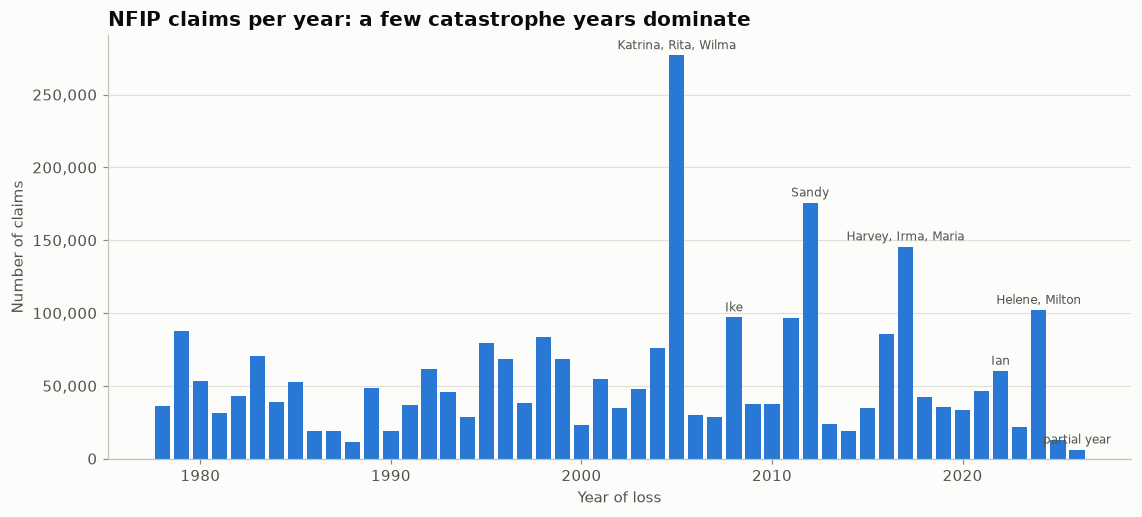

In [8]:
per_year = claims.groupby("yearOfLoss").size()
print(per_year.describe().round(0))
print("\nTop 10 years by number of claims:")
print(per_year.sort_values(ascending=False).head(10))

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(per_year.index, per_year.values, color=BLUE, width=0.8)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.set_xlabel("Year of loss")
ax.set_ylabel("Number of claims")
ax.set_title("NFIP claims per year: a few catastrophe years dominate")
ax.grid(axis="x", visible=False)

events = {2005: "Katrina, Rita, Wilma", 2012: "Sandy", 2017: "Harvey, Irma, Maria",
          2008: "Ike", 2022: "Ian", 2024: "Helene, Milton",
          int(per_year.index.max()): "partial year"}
for yr, label in events.items():
    if yr in per_year.index:
        ax.annotate(label, (yr, per_year[yr]), xytext=(0, 4), textcoords="offset points",
                    ha="center", fontsize=8, color=INK_2)
save(fig, "claims_per_year")
plt.show()

## 5. Claims by state

58 states/territories. Top 5 share of all claims: 63%
Virginia: 50,609 claims, rank 12


saved reports\figures\01_claims_by_state.png


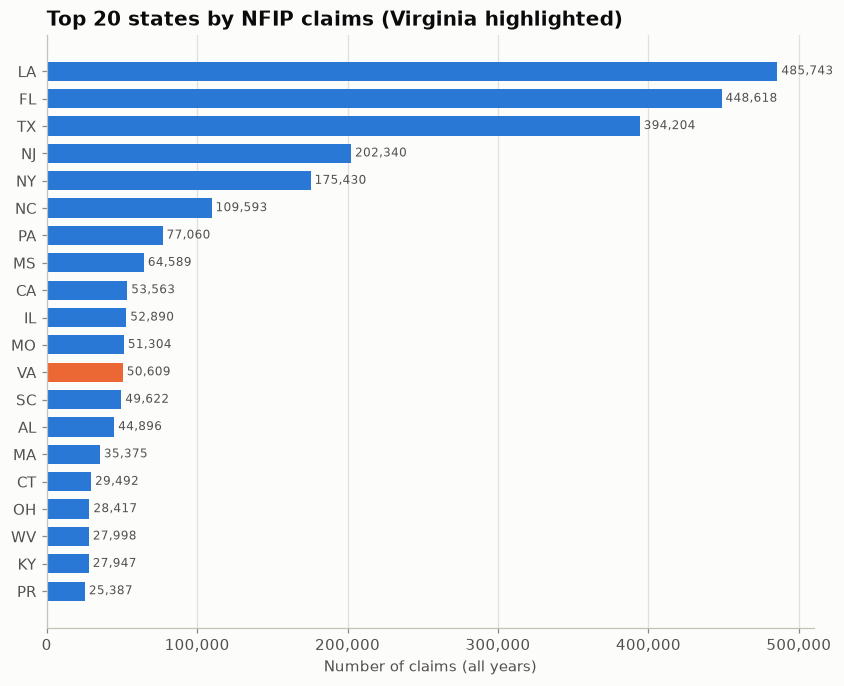

In [9]:
by_state = claims.groupby("state").size().sort_values(ascending=False)
print(f"{by_state.size} states/territories. Top 5 share of all claims: "
      f"{by_state.head(5).sum() / by_state.sum():.0%}")
print(f"Virginia: {by_state.get('VA', 0):,} claims, rank {list(by_state.index).index('VA') + 1}")

top = by_state.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 7))
colors = [ORANGE if s == "VA" else BLUE for s in top.index]
ax.barh(top.index, top.values, color=colors, height=0.7)
ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax.set_xlabel("Number of claims (all years)")
ax.set_title("Top 20 states by NFIP claims (Virginia highlighted)")
ax.grid(axis="y", visible=False)
for y, v in enumerate(top.values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=INK_2)
save(fig, "claims_by_state")
plt.show()

## 6. Top counties: nationally and in Virginia

Counties are identified by **FIPS codes**: 5 digits, where the first 2 are the state (Virginia = 51) and the last 3 are the county. The names below come from a small lookup table typed into this notebook (Census Bureau names), so we don't need an extra download.

> Note: in Virginia, **independent cities** (like Virginia Beach, Norfolk, Hampton) are county-level areas with their own FIPS codes. That's why cities show up in a "county" ranking.

In [10]:
# FIPS code -> county name, for the counties that appear in the rankings below.
COUNTY_NAMES = {'12011': 'Broward County, FL',
 '12071': 'Lee County, FL',
 '12086': 'Miami-Dade County, FL',
 '12087': 'Monroe County, FL',
 '12103': 'Pinellas County, FL',
 '22051': 'Jefferson Parish, LA',
 '22071': 'Orleans Parish, LA',
 '22087': 'St. Bernard Parish, LA',
 '22103': 'St. Tammany Parish, LA',
 '34009': 'Cape May County, NJ',
 '34029': 'Ocean County, NJ',
 '36059': 'Nassau County, NY',
 '36103': 'Suffolk County, NY',
 '48167': 'Galveston County, TX',
 '48201': 'Harris County, TX',
 '51001': 'Accomack County',
 '51059': 'Fairfax County',
 '51073': 'Gloucester County',
 '51115': 'Mathews County',
 '51161': 'Roanoke County',
 '51199': 'York County',
 '51550': 'Chesapeake city',
 '51650': 'Hampton city',
 '51700': 'Newport News city',
 '51710': 'Norfolk city',
 '51735': 'Poquoson city',
 '51740': 'Portsmouth city',
 '51770': 'Roanoke city',
 '51775': 'Salem city',
 '51810': 'Virginia Beach city'}

def county_label(fips):
    return f"{COUNTY_NAMES.get(fips, 'FIPS ' + str(fips))} ({fips})"

by_county = claims.dropna(subset=["countyCode"]).groupby("countyCode").size().sort_values(ascending=False)
top_us = by_county.head(15)
va_claims = claims[claims.state == "VA"]
top_va = va_claims.dropna(subset=["countyCode"]).groupby("countyCode").size().sort_values(ascending=False).head(15)
print("Top 15 counties nationally:"); print(top_us)
print("\nTop 15 counties in Virginia:"); print(top_va)
print(f"\nTop 15 VA areas' share of all VA claims: {top_va.sum() / len(va_claims):.0%}")

Top 15 counties nationally:
countyCode
48201    170854
22051    135664
22071    127255
12086     62029
48167     60620
34029     52884
12103     51779
36059     51523
12071     48496
22103     38420
12011     35049
36103     33936
34009     28016
12087     27430
22087     23919
dtype: int64

Top 15 counties in Virginia:
countyCode
51810    6260
51710    6019
51650    5774
51735    4290
51550    2634
51740    1748
51199    1569
51059    1488
51073    1378
51770    1184
51115    1162
51001    1114
51700    1065
51775     812
51161     583
dtype: int64

Top 15 VA areas' share of all VA claims: 73%


saved reports\figures\01_top_counties.png


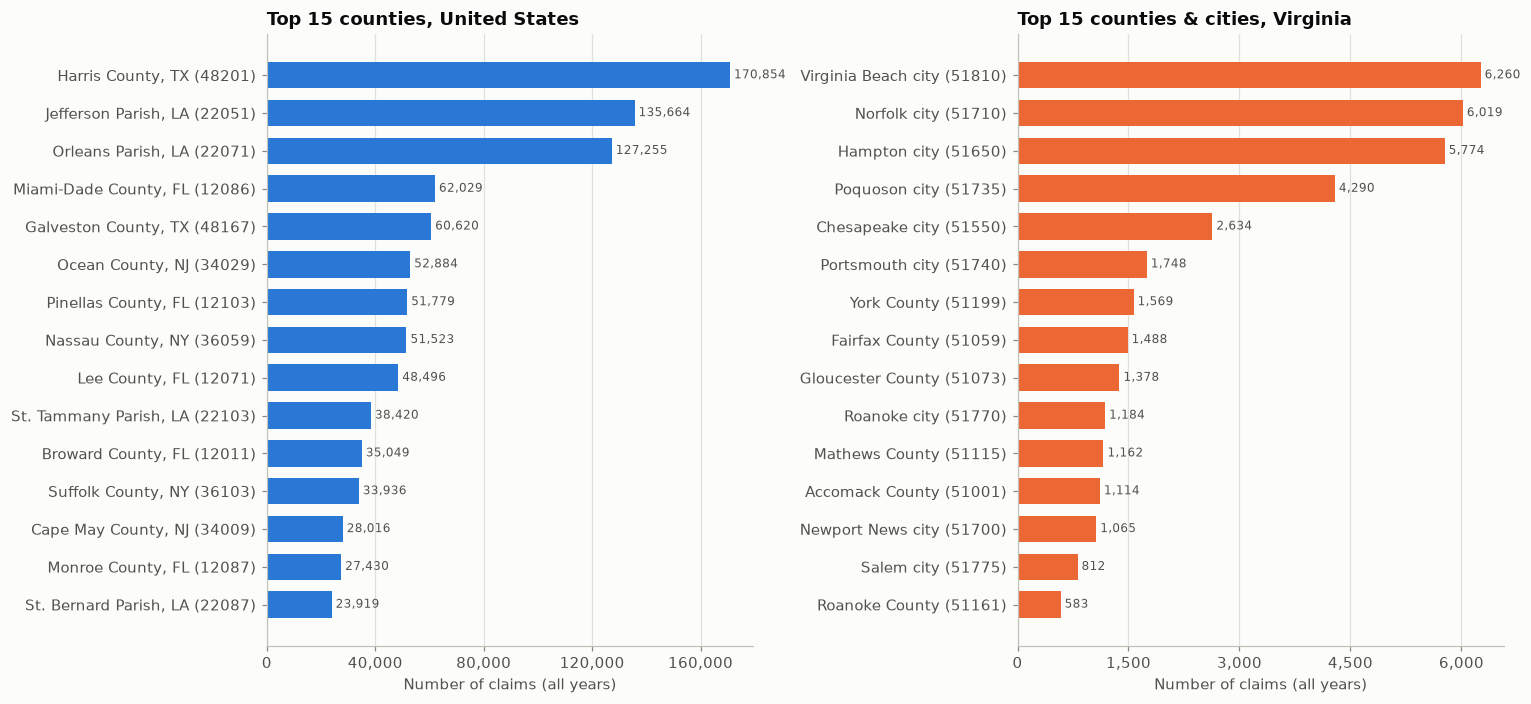

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))
for ax, (title, s, color) in zip(axes, [("Top 15 counties, United States", top_us, BLUE),
                                        ("Top 15 counties & cities, Virginia", top_va, ORANGE)]):
    t = s.iloc[::-1]
    ax.barh([county_label(c) for c in t.index], t.values, color=color, height=0.7)
    ax.xaxis.set_major_locator(mticker.MaxNLocator(5))
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(thousands))
    ax.set_xlabel("Number of claims (all years)")
    ax.set_title(title, fontsize=12)
    ax.grid(axis="y", visible=False)
    for y, v in enumerate(t.values):
        ax.text(v, y, f" {v:,}", va="center", fontsize=8, color=INK_2)
fig.tight_layout()
save(fig, "top_counties")
plt.show()

## 7. How big are claim payments? (and why a log scale)

**Total paid** per claim = building payment + contents payment + ICC payment (ICC is extra money for rebuilding to code).

Many claims are closed **without payment** (for example, the damage was less than the deductible). We look at those separately and then plot only claims with a payment above $0.

**Why a log scale?** Claim sizes are **right-skewed**: most claims are modest, but a few are enormous (hundreds of thousands of dollars). On an ordinary axis, nearly every bar gets squashed into the left edge and the big claims are invisible. On a **log scale**, each step along the axis multiplies the value by 10 ($100 → $1,000 → $10,000 → …). Equal distances then mean equal *ratios*, so small and large claims are both visible on one chart. The left panel below shows the problem and the right panel shows the fix.

In [12]:
pay_cols = ["amountPaidOnBuildingClaim", "amountPaidOnContentsClaim",
            "amountPaidOnIncreasedCostOfComplianceClaim"]
claims["total_paid"] = claims[pay_cols].fillna(0).sum(axis=1)

n = len(claims)
print(f"Claims with total paid > $0:  {(claims.total_paid > 0).sum():,} ({(claims.total_paid > 0).mean():.1%})")
print(f"Claims with total paid = $0:  {(claims.total_paid == 0).sum():,} ({(claims.total_paid == 0).mean():.1%})")
print(f"Claims with total paid < $0:  {(claims.total_paid < 0).sum():,}")

paid = claims.loc[claims.total_paid > 0, "total_paid"]
summary = paid.describe(percentiles=[0.1, 0.25, 0.5, 0.75, 0.9, 0.99])
print("\nPaid claims ($, nominal, not inflation-adjusted):")
print(summary.apply(lambda v: f"{v:,.0f}"))
print(f"\nMean / median = {paid.mean() / paid.median():.2f}  (a mean far above the median is a sign of right skew)")
print(f"Share of all dollars paid by the largest 10% of claims: "
      f"{paid[paid >= paid.quantile(0.9)].sum() / paid.sum():.0%}")

Claims with total paid > $0:  2,117,326 (77.7%)
Claims with total paid = $0:  608,577 (22.3%)
Claims with total paid < $0:  86

Paid claims ($, nominal, not inflation-adjusted):
count     2,117,326
mean         42,443
std          85,038
min               0
10%           1,182
25%           3,609
50%          13,042
75%          49,515
90%         118,302
99%         335,869
max      10,841,477
Name: total_paid, dtype: str

Mean / median = 3.25  (a mean far above the median is a sign of right skew)
Share of all dollars paid by the largest 10% of claims: 51%


saved reports\figures\01_claim_payment_distribution.png


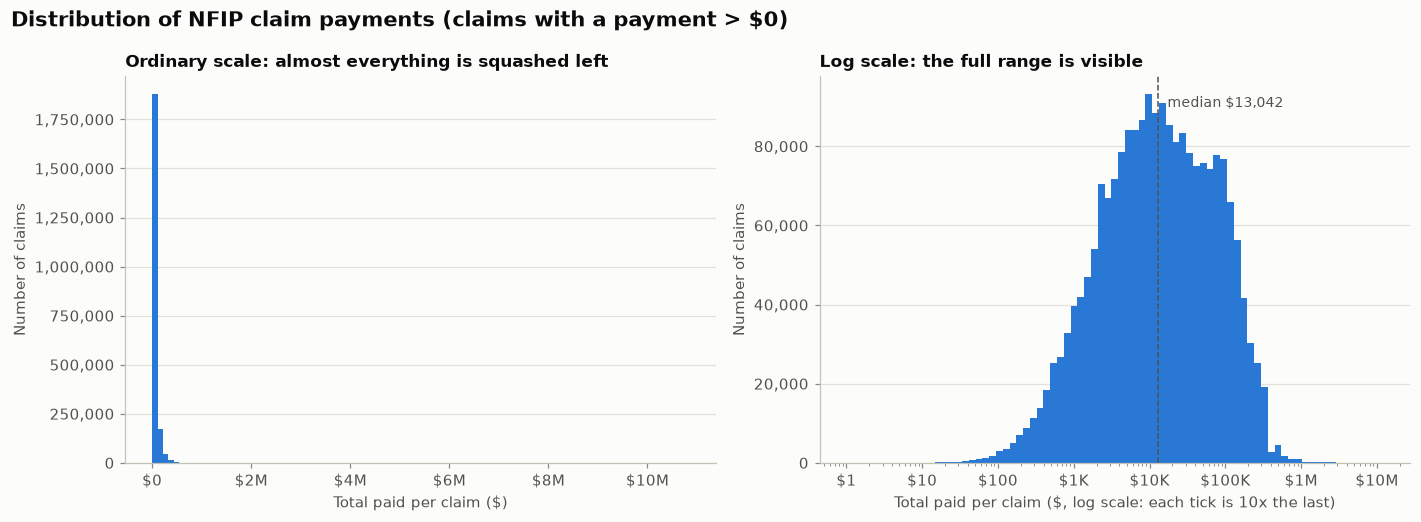

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

# Left: ordinary (linear) axis
ax1.hist(paid, bins=100, color=BLUE)
ax1.set_title("Ordinary scale: almost everything is squashed left", fontsize=11)
ax1.set_xlabel("Total paid per claim ($)")
ax1.set_ylabel("Number of claims")
ax1.xaxis.set_major_formatter(mticker.FuncFormatter(dollars_short))
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))

# Right: log-scale x axis (bins evenly spaced on the log scale)
bins = np.logspace(0, np.log10(paid.max()) + 0.05, 80)
ax2.hist(paid, bins=bins, color=BLUE)
ax2.set_xscale("log")
ax2.set_title("Log scale: the full range is visible", fontsize=11)
ax2.set_xlabel("Total paid per claim ($, log scale: each tick is 10x the last)")
ax2.set_ylabel("Number of claims")
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(dollars_short))
ax2.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
med = paid.median()
ax2.axvline(med, color=INK_2, linewidth=1, linestyle="--")
ax2.annotate(f"median ${med:,.0f}", (med, ax2.get_ylim()[1] * 0.92), xytext=(6, 0),
             textcoords="offset points", fontsize=9, color=INK_2)
for ax in (ax1, ax2):
    ax.grid(axis="x", visible=False)
fig.suptitle("Distribution of NFIP claim payments (claims with a payment > $0)", x=0.01, ha="left",
             fontsize=14, fontweight="bold", color=INK)
fig.tight_layout()
save(fig, "claim_payment_distribution")
plt.show()

## 8. Virginia: claims, policies, and a first look at exposure

**Exposure** is the amount of risk we're insuring: here, how many policies are in force. A county with many claims might simply have many policies. Dividing claims by policies gives a **claim rate** that we can compare fairly across areas and years.

Here we count policies by the year their term started, adding up `policyCount` (a condo master policy counts as several units). This is a rough first measure, refined in the cleaning step.

      policies  claims  claims_per_1000_policies
2009    110453    6719                     60.83
2010    112642     430                      3.82
2011    115910    3395                     29.29
2012    117540    1484                     12.63
2013    117091     355                      3.03
2014    115900     479                      4.13
2015    110255     524                      4.75
2016    108333    2806                     25.90
2017    109170     162                      1.48
2018    110014     848                      7.71
2019    107280     413                      3.85
2020    105007     605                      5.76
2021    103286     228                      2.21
2022     99176     185                      1.87
2023     94708     107                      1.13
2024     94249     272                      2.89
2025     92259     252                      2.73


saved reports\figures\01_va_policies_and_claim_rate.png


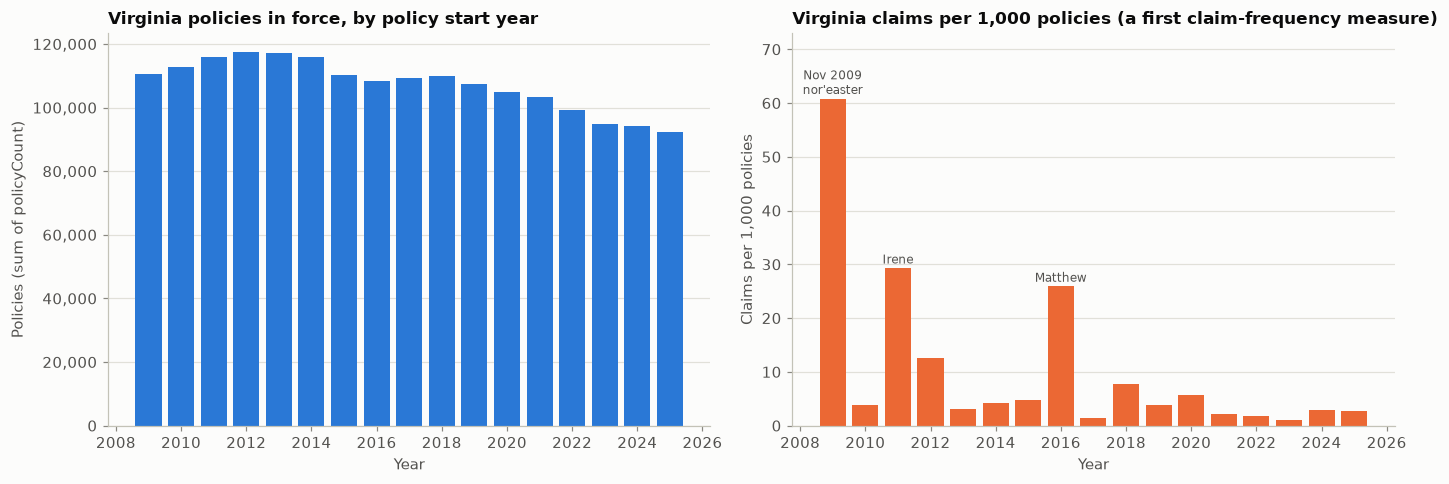

In [14]:
policies["eff_year"] = policies["policyEffectiveDate"].dt.year
va_pol_year = policies.groupby("eff_year")["policyCount"].sum()
va_clm_year = va_claims.groupby("yearOfLoss").size()
va = pd.DataFrame({"policies": va_pol_year, "claims": va_clm_year}).dropna()
va = va[va.index < 2026]               # 2026 is incomplete (claims so far only run to September)
va["claims_per_1000_policies"] = va.claims / va.policies * 1000
print(va.astype({"policies": int, "claims": int}).round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.bar(va.index, va.policies, color=BLUE, width=0.8)
ax1.set_title("Virginia policies in force, by policy start year", fontsize=11)
ax1.set_ylabel("Policies (sum of policyCount)")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(thousands))
ax2.bar(va.index, va.claims_per_1000_policies, color=ORANGE, width=0.8)
ax2.set_title("Virginia claims per 1,000 policies (a first claim-frequency measure)", fontsize=11)
ax2.set_ylabel("Claims per 1,000 policies")
ax2.set_ylim(0, va.claims_per_1000_policies.max() * 1.2)   # headroom for labels
for ax in (ax1, ax2):
    ax.set_xlabel("Year")
    ax.xaxis.set_major_locator(mticker.MaxNLocator(integer=True))
    ax.grid(axis="x", visible=False)
for yr, label in {2009: "Nov 2009\nnor'easter", 2011: "Irene", 2016: "Matthew"}.items():
    if yr in va.index:
        ax2.annotate(label, (yr, va.loc[yr, "claims_per_1000_policies"]), xytext=(0, 3),
                     textcoords="offset points", ha="center", fontsize=8, color=INK_2)
fig.tight_layout()
save(fig, "va_policies_and_claim_rate")
plt.show()

                             % of VA policies  % of VA claims
High risk (A)                           52.00           74.40
High risk coastal (V)                    1.00            1.50
Moderate/low risk (B, C, X)             47.00           20.70
Not reported                             0.00            3.30
Other (D, etc.)                          0.00            0.00
saved reports\figures\01_va_flood_zone_mix.png


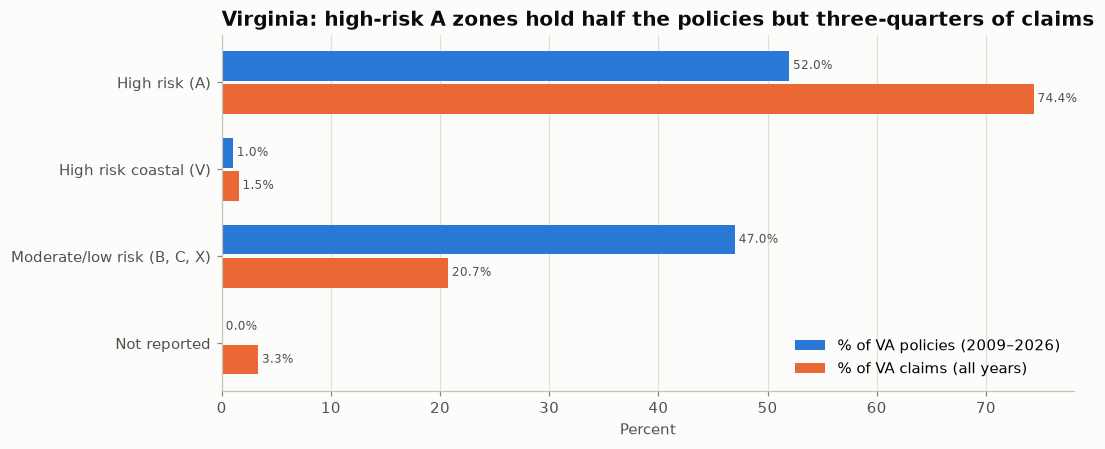

In [15]:
def zone_group(z):
    # Collapse detailed FEMA flood zones into four plain-English groups
    if pd.isna(z) or z.strip() == "":
        return "Not reported"
    z = z.strip().upper()
    if z.startswith("V"):
        return "High risk coastal (V)"
    if z.startswith("A"):
        return "High risk (A)"
    if z[0] in "BCX":
        return "Moderate/low risk (B, C, X)"
    return "Other (D, etc.)"

policies["zone_group"] = policies["ratedFloodZone"].map(zone_group)
zone_mix = policies.groupby("zone_group")["policyCount"].sum().astype(float)

claims_va_zone = va_claims["ratedFloodZone"].map(zone_group).value_counts()
compare = pd.DataFrame({"% of VA policies": zone_mix / zone_mix.sum() * 100,
                        "% of VA claims": claims_va_zone / claims_va_zone.sum() * 100}).fillna(0)
print(compare.round(1))

# Compare: share of policies vs. share of claims in each zone group
order = ["High risk (A)", "High risk coastal (V)", "Moderate/low risk (B, C, X)", "Not reported"]
cmp = compare.reindex(order).fillna(0)
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(order))
h = 0.38
ax.barh(y - h / 2, cmp["% of VA policies"], height=h - 0.04, color=BLUE, label="% of VA policies (2009–2026)")
ax.barh(y + h / 2, cmp["% of VA claims"], height=h - 0.04, color=ORANGE, label="% of VA claims (all years)")
ax.set_yticks(y, order)
ax.invert_yaxis()
ax.set_xlabel("Percent")
ax.set_title("Virginia: high-risk A zones hold half the policies but three-quarters of claims")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
for yi, (pv, cv) in enumerate(zip(cmp["% of VA policies"], cmp["% of VA claims"])):
    ax.text(pv, yi - h / 2, f" {pv:.1f}%", va="center", fontsize=8, color=INK_2)
    ax.text(cv, yi + h / 2, f" {cv:.1f}%", va="center", fontsize=8, color=INK_2)
save(fig, "va_flood_zone_mix")
plt.show()

## Takeaways

The main findings are written up in `reports/01_data_overview.md`. Next step: build a cleaned dataset with exposure and claims summarised by area and year, so we can model **frequency** (claims per policy) and **severity** (dollars per claim).